## Setup (run this first)
This cell finds the project files automatically: current folder, then the group GitHub repo, then a shared Drive folder, then a zip upload. Everyone (group members and the instructor) can run it without editing paths.

In [ ]:
# ---- Setup: works for any group member, the instructor, Colab or a laptop ------------------------------
# Order tried: (1) the files are already in the current folder, (2) Member3_Baseline_NLP.zip is already uploaded
# (Colab file panel or next to this notebook), (3) the shared Google Drive zip (downloaded, no sign-in),
# (4) the group GitHub repo, (5) an already-mounted Drive folder, (6) you upload the zip when asked. Nothing needs editing.
import os, sys, glob, zipfile, subprocess
REPO_URL = os.environ.get("REPO_URL", "https://github.com/jijjira/anlp-at2b-study-to-career.git")
DRIVE_DIR = "/content/drive/MyDrive/ANLP AT2B"
DRIVE_ZIP_ID = "1pgnI7O_CHeXK7RRtrGqA-XA7dKOvW6G_"   # Member3_Baseline_NLP.zip in the shared Drive folder
NEEDED = ["extraction.py", "make_sample_pdf.py", "skill_extractor.py", "skill_extractor_v2.py", "analysis.py", "evaluate.py",
          "gold_annotations.py", "job_cleaned.csv", "skills_dictionary.csv", "normalisation.py",
          "extra_aliases_reviewed.csv", "gold_split.json"]
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False
def have_all(d="."): return all(os.path.exists(os.path.join(d, f)) for f in NEEDED)
def use(folder): os.chdir(folder); print("Using folder:", os.getcwd())
def code_folder(root):
    hits = glob.glob(os.path.join(root, "**", "skill_extractor_v2.py"), recursive=True)
    return os.path.dirname(hits[0]) if hits else None
def from_zip(z):
    out = "/content/m3" if IN_COLAB else os.path.join(os.path.dirname(os.path.abspath(z)), "_m3")
    zipfile.ZipFile(z).extractall(out); f = code_folder(out)
    if f: use(f)
START = os.getcwd()
if not have_all():                                   # (2) a zip that is already there
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        if "Member3" in os.path.basename(z) and not have_all(): from_zip(z)
if not have_all():                                   # (3) the public Drive zip (one file, no sign-in needed)
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=False)
        import gdown
        zdir = "/content" if IN_COLAB else START
        zp = gdown.download(id=DRIVE_ZIP_ID, output=os.path.join(zdir, "Member3_Baseline_NLP.zip"), quiet=True)
        if zp and zipfile.is_zipfile(zp): from_zip(zp)
        else: print("Could not download the zip from Drive, trying the next option.")
    except Exception:
        print("Could not download the zip from Drive, trying the next option.")
if not have_all():                                   # (4) group repo (works only if it is public or you are signed in)
    dest = "/content/_repo" if IN_COLAB else os.path.join(START, "_repo")
    if not os.path.exists(dest):
        env = dict(os.environ, GIT_TERMINAL_PROMPT="0")
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, dest], capture_output=True, text=True, env=env)
        if r.returncode != 0: print("Could not clone the repo (it may be private), trying the next option.")
    f = code_folder(dest) if os.path.exists(dest) else None
    if f: use(f)
if not have_all() and os.path.isdir(DRIVE_DIR) and have_all(DRIVE_DIR): use(DRIVE_DIR)   # (5) Drive, only if already mounted
if not have_all() and IN_COLAB:                      # (6) ask for the zip; never save into the Drive mount
    os.chdir("/content")
    print("Please choose Member3_Baseline_NLP.zip (from the group Drive or the submission).")
    from google.colab import files
    for name in files.upload():
        if name.endswith(".zip") and not have_all(): from_zip(os.path.join("/content", name))
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spacy", "pymupdf", "reportlab"], check=False)
missing = [f for f in NEEDED if not os.path.exists(f)]
print("Working folder:", os.getcwd()); print("Missing files:", missing if missing else "none, good to go")


# 05 · Student-side pipeline: PDF study material → skills (Member 3)
The team division gives Member 3 two jobs: the job-ad extractor (notebooks 03 and 04) **and** the extraction of text from uploaded PDF study materials with PyMuPDF. This notebook covers the second job and shows that the **same matching logic** is used on both sides.

Pipeline: `PDF → PyMuPDF text per page → clean (headers/footers, page numbers, hyphenation, soft line wraps, one sentence per line) → PhraseMatcher + reviewed aliases → canonical skills with page evidence`.

Wording rule for the UI (Member 6): these are **skills covered by your study materials**, not skills the student has mastered.

### 1. A synthetic unit outline (no real student data)

In [2]:
from extraction import *
from make_sample_pdf import build
PDF = build("sample_unit_outline.pdf")      # to use your own file, set PDF = "my_unit_outline.pdf"
raw = read_pdf_pages(PDF); clean = clean_pages(raw)
print("pages:", len(raw)); print("--- RAW page 1 ---"); print(raw[0][:420]); print("--- CLEANED page 1 ---"); print(clean[0][:420])

pages: 5
--- RAW page 1 ---
UTS 36XXX Machine Learning Foundations - Unit Outline


      Unit overview
        This unit is an introduction to applied machine learning. Students may have seen Git before.

     Learning outcomes
       By the end of this unit students will be able to build and evaluate a regression model in Python.





Page 1
--- CLEANED page 1 ---
Unit overview
This unit is an introduction to applied machine learning.
Students may have seen Git before.
Learning outcomes
By the end of this unit students will be able to build and evaluate a regression model in Python.


The raw text still has the running header, the page number and hard line wraps. The cleaned text has none of them, and one sentence per line, so the ambiguity guard works per sentence.

### 2. Skills covered, with page evidence

In [3]:
import pandas as pd
prof = analyse_study_material(PDF)
tbl = pd.DataFrame([{"skill": s, "category": prof.skills[s]["category"], "mentions": prof.skills[s]["mentions"],
                     "pages": prof.skills[s]["pages"], "evidence": prof.skills[s]["evidence"][:90]} for s in prof.names()])
print(len(tbl), "skills covered; warnings:", prof.warnings or "none"); tbl

24 skills covered; warnings: none


,skill,category,mentions,pages,evidence
0,Regression,Data Analysis & Statistics,3,"[1, 3]",By the end of this unit students will be able ...
1,Deep Learning,Machine Learning & AI,2,[4],Week 3: Deep learning
2,Docker,MLOps / Deployment,2,[5],Assessment 2 is a model deployed with Docker.
3,Machine Learning,Machine Learning & AI,2,"[1, 3]",The unit covers machine learning fundamentals:...
4,Python,Programming,2,"[1, 2]",By the end of this unit students will be able ...
5,AWS,Cloud,1,[5],"Students package models with Docker, deploy on..."
6,Apache Spark,Data Engineering,1,[4],The unit introduces natural language processin...
7,Dashboarding,Data Visualisation / BI,1,[5],Assessment 1 is a group project presented in T...
8,Data Analysis,Data Analysis & Statistics,1,[2],Exploratory data analysis is introduced with m...
9,EDA,Data Analysis & Statistics,1,[2],Exploratory data analysis is introduced with m...


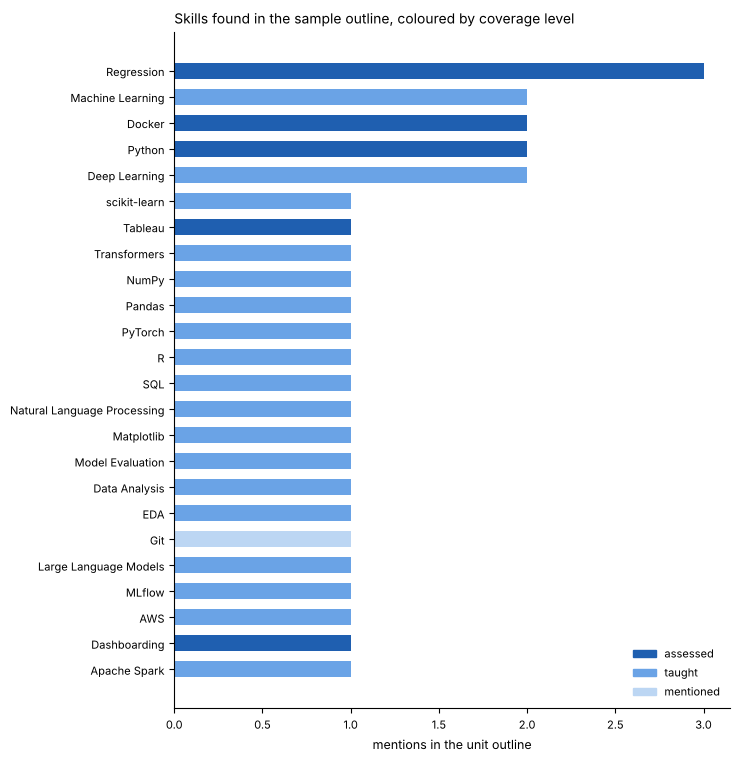

In [4]:
import os, matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
col = {"assessed": "#1f5fb0", "taught": "#6aa3e6", "mentioned": "#bcd6f3"}
d = pd.DataFrame([{"skill": s, "level": prof.skills[s]["level"], "mentions": prof.skills[s]["mentions"]} for s in prof.names()]).sort_values("mentions")
fig, ax = plt.subplots(figsize=(7.5, max(2.5, 0.28 * len(d) + 1)))
ax.barh(d.skill, d.mentions, color=[col[l] for l in d.level], height=0.62)
import matplotlib.patches as mp
ax.legend(handles=[mp.Patch(color=c, label=l) for l, c in col.items()], frameon=False, fontsize=8, loc="lower right")
ax.set_xlabel("mentions in the unit outline", fontsize=9); ax.tick_params(labelsize=8)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.set_title("Skills found in the sample outline, coloured by coverage level", loc="left", fontsize=10)
plt.tight_layout(); fig.savefig("figures/fig0b_sample_outline_coverage.png", dpi=200, bbox_inches="tight"); plt.show()

Things the pipeline gets right in this file: `R&D` is **not** read as the language R; the verb in "we will spark discussion" is **not** read as Apache Spark, while "the Spark ecosystem" is; `Page 3` and the running header are removed.

### 3. Same logic on the job side (consistency check)

In [5]:
from skill_extractor import extract_skills
sentence = "Experience with Python, SQL and PyTorch on AWS."
print("job-side baseline :", extract_skills(sentence))
print("student-side      :", list(analyse_text(sentence).skills))
assert set(extract_skills(sentence)) == set(analyse_text(sentence).skills)

job-side baseline : ['Python', 'SQL', 'PyTorch', 'AWS']
student-side      : ['Python', 'SQL', 'PyTorch', 'AWS']


### 4. Link to career matching (Step 5)
The student profile plugs straight into the demand-weighted career profiles from notebook 04. This is only a demo of the interface, not the final matching method.

In [6]:
import numpy as np
from analysis import corpus_tables, profiles
S, RAW = corpus_tables(); P = profiles(S, RAW)
def fit(K, c, topn=30):
    g = P[P.career == c].nlargest(topn, "demand_weight"); return g[g.skill.isin(K)].demand_weight.sum() / g.demand_weight.sum()
K = set(prof.skills)
fits = pd.Series({c: fit(K, c) for c in sorted(P.career.unique())}).sort_values(ascending=False)
print("Career fit from the PDF alone (0-1):"); print(fits.round(2).to_string())
best = fits.index[0]
print(f"\nLargest gaps for {best}:")
P[(P.career == best) & (~P.skill.isin(K))].nlargest(5, "demand_weight")[["skill", "demand_weight"]].round(2)

Career fit from the PDF alone (0-1):
Data Scientist    0.52
ML Engineer       0.50
Data Analyst      0.48
Data Engineer     0.30
AI Engineer       0.25

Largest gaps for Data Scientist:


,skill,demand_weight
310,Statistics,0.60
333,Artificial Intelligence,0.49
292,Causal Inference,0.46
297,A/B Testing,0.23
312,Experiment Design,0.21


### 5. Limitations of the student-side pipeline
* **Scanned PDFs** (images of pages) contain no text layer; the code warns but does not run OCR.
* **Slides and multi-column layouts** can interleave text; `sort=True` helps but is not perfect.
* **Exact-phrase matching only**: concepts taught without naming the skill ("we fit a line to the data") are missed. That is the gap the semantic method (Member 4) targets.
* A mention is not mastery: a unit that merely *mentions* Docker is counted as "covered".
* Tested on a synthetic PDF and unit tests only, not yet on real student PDFs. Run it on 3 to 5 real outlines before the demo.